# Transformaciones de datos con PyTorch
## Objetivos
- aplicar transformaciones de datos con `torchvision.transforms`,
- visualizar ejemplos de imágenes transformadas,
- preparar un `DataLoader` para entrenamiento.

In [1]:
# 1. Configuración inicial
import numpy as np
import matplotlib.pyplot as plt
import torch

from torchvision import datasets
from torchvision import transforms as tfs
from torch.utils import data

plt.style.use('ggplot')

from _bootstrap import setup
from src.vasijas.reporting import ProcessingReport

IMG_SIZE = 128
FLIP_PROBABILITY = 0.7
SCALING_FACTOR_INTERVAL = (0.7, 1.)
ROTATION_DEGREES = (0, 360)
PIXEL_FILL = (255, 255, 255)

PATHS = setup()
report = ProcessingReport()

#Configuración general
available_device = "cuda" if torch.cuda.is_available() else "cpu"

In [2]:
# 2. Transformaciones y DataLoader
transformations = [tfs.RandomHorizontalFlip(p=FLIP_PROBABILITY),
                   tfs.RandomAffine(0, scale=SCALING_FACTOR_INTERVAL, fill=PIXEL_FILL),
                   tfs.RandomRotation(degrees=ROTATION_DEGREES, fill=PIXEL_FILL),
                   tfs.Resize((IMG_SIZE, IMG_SIZE))]

imagenet_data = datasets.ImageFolder(PATHS.DATA_CENTRADOS, transform=tfs.Compose(transformations))

data_loader = data.DataLoader(imagenet_data, batch_size=4, shuffle=True)

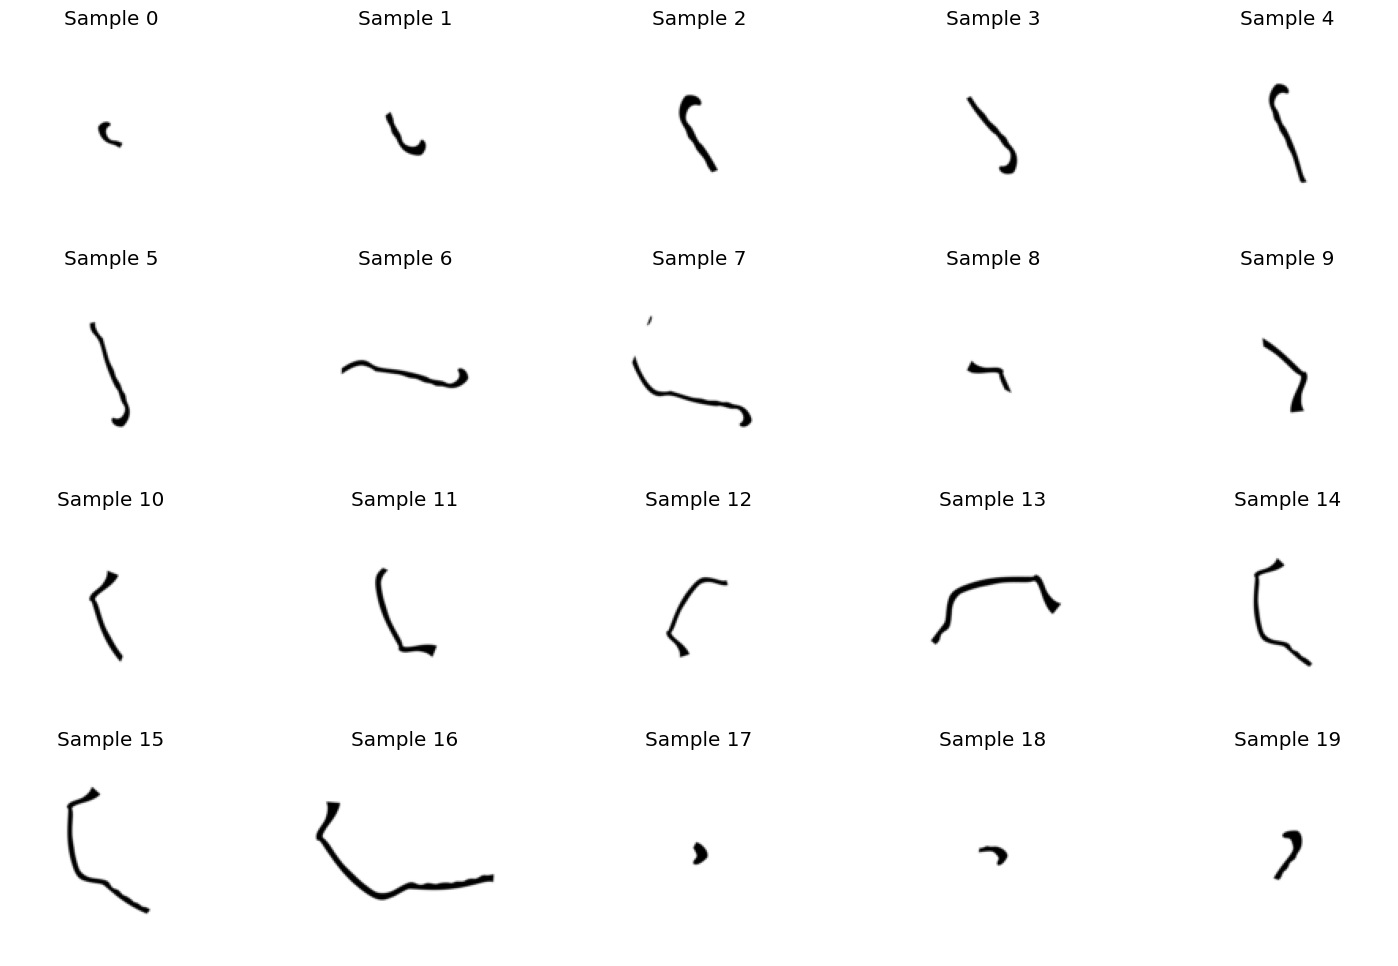

In [3]:
# 3. Visualización rápida (sanity check)
fig = plt.figure(figsize=(15, 10))

n_samples = min(20, max(0, len(imagenet_data) - 10))  # por el offset i+10

for i in range(n_samples):
    sample = imagenet_data[i + 10]  # (imagen, etiqueta)
    ax = plt.subplot(4, 5, i + 1)  # 4 filas x 5 columnas = 20
    plt.tight_layout()
    plt.imshow(np.asarray(sample[0]), cmap=plt.cm.gray_r)
    ax.set_title(f"Sample {i}")
    ax.axis("off")

plt.show()